# 字符语言模型：接着写下一个字

目标：把文字变成编号，让模型根据前面的字预测下一个字，最后从“小猫”开始续写。

从项目根目录运行；`device` 可以改为 `"cpu"` 或 `"cuda"`。

In [2]:
from qutai import Stream, lm, nn, visualization

device = "apple"

## 1. 看训练数据

每个字符对应一个编号。`Stream` 每次取 8 个字符作为输入，目标向后错开一个字符；例如输入“小猫”，目标就是“猫喜”。这里重复一小段文字，让我们容易看出模型在学什么。

In [3]:
text = "小猫喜欢晒太阳。小狗喜欢追皮球。\n" * 8
tokenizer = lm.Tokenizer(text)
# Stream 自动把每段文字错开一位，得到下一字标签。
data = Stream(tokenizer.encode(text), context_length=8, batch_size=4, device=device)
inputs, targets = next(iter(data))

visualization.Table(list(zip(tokenizer.decode(inputs[0]), tokenizer.decode(targets[0]))), columns=["输入字符", "下一个字符"])

输入字符,下一个字符
喜,欢
欢,晒
晒,太
太,阳
阳,。
。,小
小,狗
狗,喜


## 2. 搭模型

`lm.Model` 已经把字符嵌入、位置、因果 Transformer 和输出层串好。输出是在每个位置预测下一个字符的得分，`CrossEntropy` 用这些得分和正确编号计算损失。

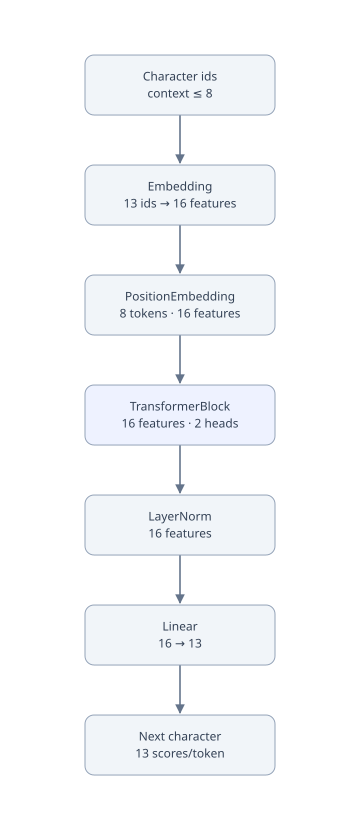

In [5]:
model = lm.Model(tokenizer, context_length=8, features=16, heads=2, hidden_features=32, device=device)
optimizer = nn.AdamW(model, learning_rate=0.01)
loss_function = nn.CrossEntropy()

visualization.Network(model)

## 3. 训练

外层是一轮完整遍历，内层从 `Stream` 取一批文字。每批仍是熟悉的四步：清梯度、算损失、反向、更新参数。

In [6]:
epochs = 50

# 每轮遍历一次数据；每批独立完成一次参数更新。
for epoch in range(epochs):
    for inputs, targets in data:
        optimizer.zero_grad()
        loss = loss_function(model(inputs), targets)
        loss.backward()
        optimizer.step()
    print(f"epoch {epoch + 1}/{epochs}  loss {loss.item():.4f}")

epoch 1/50  loss 2.5518
epoch 2/50  loss 1.7969
epoch 3/50  loss 1.4535
epoch 4/50  loss 1.0610
epoch 5/50  loss 0.8827
epoch 6/50  loss 0.6827
epoch 7/50  loss 0.5055
epoch 8/50  loss 0.4034
epoch 9/50  loss 0.2703
epoch 10/50  loss 0.2885
epoch 11/50  loss 0.1732
epoch 12/50  loss 0.1865
epoch 13/50  loss 0.1422
epoch 14/50  loss 0.1530
epoch 15/50  loss 0.0948
epoch 16/50  loss 0.1105
epoch 17/50  loss 0.1084
epoch 18/50  loss 0.0528
epoch 19/50  loss 0.0733
epoch 20/50  loss 0.0734
epoch 21/50  loss 0.1559
epoch 22/50  loss 0.1430
epoch 23/50  loss 0.0708
epoch 24/50  loss 0.0400
epoch 25/50  loss 0.0296
epoch 26/50  loss 0.0406
epoch 27/50  loss 0.0358
epoch 28/50  loss 0.0963
epoch 29/50  loss 0.1006
epoch 30/50  loss 0.1442
epoch 31/50  loss 0.0397
epoch 32/50  loss 0.0672
epoch 33/50  loss 0.0771
epoch 34/50  loss 0.1267
epoch 35/50  loss 0.0647
epoch 36/50  loss 0.0292
epoch 37/50  loss 0.1193
epoch 38/50  loss 0.0956
epoch 39/50  loss 0.0529
epoch 40/50  loss 0.0966
epoch 41/

## 4. 续写

默认每次选择得分最高的字。加上 `temperature` 和 `top_k` 可以随机采样，让续写有变化。小语料只用于理解流程，不能代表通用语言能力。

In [13]:
print(model.generate("小猫", length=30))
print(model.generate("小猫", length=30, temperature=0.8, top_k=3))

小猫喜欢晒太阳。小狗喜欢追皮球。
小猫喜欢晒太阳。小狗喜欢追皮球
小猫喜欢晒太阳。小狗喜欢追皮球。
小猫喜欢晒太阳。小狗喜欢追皮球
